In [17]:
import numpy as np
import matplotlib.pyplot as plt

EPS = 1e-10
MAX_ITER = 1000

In [49]:
def bisection_method(f, a, b, eps=1e-10, max_iter=1000):
    fa = f(a)
    fb = f(b)

    if fa * fb > 0:
        raise ValueError("На концах отрезка нет смены знака")

    residual_history = []
    it = 0

    while (b - a) / 2 > eps and it < max_iter:
        c = (a + b) / 2
        fc = f(c)

        residual_history.append(abs(fc))   # невязка в середине отрезка

        if abs(fc) < eps:
            return c, it + 1, residual_history

        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

        it += 1

    x = (a + b) / 2
    residual_history.append(abs(f(x)))
    return x, it, residual_history


def newton_method(f, df, x0, eps=1e-10, max_iter=1000):
    x = x0
    residual_history = []

    for it in range(1, max_iter + 1):
        fx = f(x)
        residual_history.append(abs(fx))   # сохраняем модуль невязки

        dfx = df(x)
        if abs(dfx) < 1e-14:
            raise ZeroDivisionError(f"Производная слишком мала в точке x={x}")

        x_new = x - fx / dfx

        if abs(x_new - x) < eps and abs(f(x_new)) < eps:
            residual_history.append(abs(f(x_new)))
            return x_new, it, residual_history

        x = x_new

    return x, max_iter, residual_history

def simple_iteration_method(phi, x0, residual, eps=1e-10, max_iter=1000):
    x = x0
    residual_history = []

    for it in range(1, max_iter + 1):
        residual_history.append(abs(residual(x)))

        x_new = phi(x)

        if abs(x_new - x) < eps and abs(residual(x_new)) < eps:
            residual_history.append(abs(residual(x_new)))
            return x_new, it, residual_history

        x = x_new

    return x, max_iter, residual_history


def modified_newton_method(f, df, x0, multiplicity, eps=1e-10, max_iter=1000):
    """
    Модифицированный метод Ньютона для корня кратности m:
        x_{n+1} = x_n - m * f(x_n) / f'(x_n)

    Возвращает:
        x                - найденный корень
        it               - число итераций
        residual_history - список модулей невязки по итерациям
    """
    x = x0
    residual_history = []

    for it in range(1, max_iter + 1):
        fx = f(x)
        residual_history.append(abs(fx))

        dfx = df(x)
        if abs(dfx) < 1e-14:
            raise ZeroDivisionError(
                f"Производная слишком мала в точке x={x}"
            )

        x_new = x - multiplicity * fx / dfx

        if abs(x_new - x) < eps and abs(f(x_new)) < eps:
            residual_history.append(abs(f(x_new)))
            return x_new, it, residual_history

        x = x_new

    return x, max_iter, residual_history

In [50]:
def setup_axes(ax, title, xlabel="x", ylabel="y"):
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.35)

    # жирные черные оси
    ax.axhline(0, color="black", linewidth=2.5)
    ax.axvline(0, color="black", linewidth=2.5)


def plot_one_function(f, a, b, title, label, color="blue", n=2000, ylabel="y"):
    x = np.linspace(a, b, n)
    y = f(x)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x, y, color=color, linewidth=2, label=label)
    setup_axes(ax, title, xlabel="x", ylabel=ylabel)
    ax.legend()
    plt.show()


def plot_two_functions(f1, f2, a, b, title, label1, label2,
                       color1="blue", color2="red", n=2000):
    x = np.linspace(a, b, n)
    y1 = f1(x)
    y2 = f2(x)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x, y1, color=color1, linewidth=2, label=label1)
    ax.plot(x, y2, color=color2, linewidth=2, label=label2)
    setup_axes(ax, title)
    ax.legend()
    plt.show()


def print_result(method_name, x, iterations, residual):
    print(
        f"{method_name:<28} "
        f"x = {x: .12f}   "
        f"итераций = {iterations:3d}   "
        f"невязка = {residual(x): .3e}"
    )

In [41]:
def residual1(x):
    return x**3 - 9*x**2 + 15*x + 25


def d_residual1(x):
    return 3*x**2 - 18*x + 15

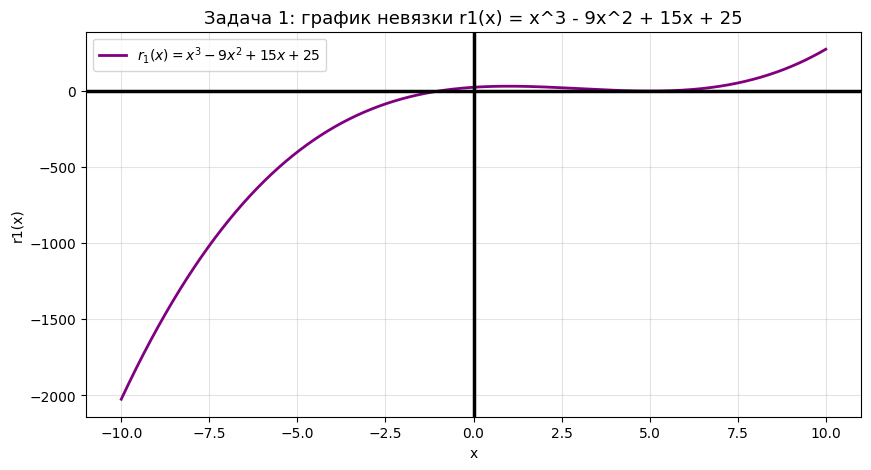

In [42]:
plot_one_function(
    residual1,
    -10,
    10,
    title="Задача 1: график невязки r1(x) = x^3 - 9x^2 + 15x + 25",
    label=r"$r_1(x)=x^3-9x^2+15x+25$",
    color="purple",
    ylabel="r1(x)"
)

In [43]:
p = [1, -9, 15, 25]
roots_np = np.roots(p)

print("Коэффициенты полинома:", p)
print("Корни через np.roots:")
for r in roots_np:
    print(r)


print("\nСледовательно:")
print("x1 = -1  — корень одинарной кратности")
print("x2 = 5   — корень двойной кратности")

Коэффициенты полинома: [1, -9, 15, 25]
Корни через np.roots:
4.9999999394711985
5.000000060528805
-1.0

Следовательно:
x1 = -1  — корень одинарной кратности
x2 = 5   — корень двойной кратности


In [45]:
root_bis_1, it_bis_1, hist_bis_1 = bisection_method(
    residual1,
    a=-1.5,
    b=-0.2
)

print("Метод дихотомии, задача 1")
print("Корень:", root_bis_1)
print("Число итераций:", it_bis_1)
print("История невязки:")
print(hist_bis_1)

Метод дихотомии, задача 1
Корень: -1.0000000000640286
Число итераций: 33
История невязки:
[5.133375000000001, 6.672859375000002, 0.45187695312500153, 2.418606201171876, 1.0030300598144564, 0.2805180549621582, 0.08444093084335691, 0.09834779876470634, 0.007030792243774897, 0.038685723590667465, 0.015822630013456518, 0.004394710065753316, 0.0013183432817918117, 0.0015381078422862515, 0.00010986339301410908, 0.0006042446661744805, 0.00024719181703147797, 6.866450711839889e-05, 2.0599369168650128e-05, 2.4032587418787443e-05, 1.7166137382673696e-06, 9.44137656233579e-06, 3.862381127817116e-06, 1.0728836272733133e-06, 3.2186507326059655e-07, 3.755092734536447e-07, 2.6822096543810403e-08, 1.475214901347499e-07, 6.034969857182659e-08, 1.6763799237651256e-08, 5.0291433240090555e-09, 5.8673279568211e-09, 4.190887636923435e-10, 2.3050290565151954e-09]


In [46]:
root_newton_1, it_newton_1, hist_newton_1 = newton_method(
    residual1,
    d_residual1,
    x0=-2.0
)

print("Метод Ньютона, задача 1, одинарный корень")
print("Корень:", root_newton_1)
print("Число итераций:", it_newton_1)
print("История невязки:")
print(hist_newton_1)

Метод Ньютона, задача 1, одинарный корень
Корень: -1.0
Число итераций: 6
История невязки:
[49.0, 8.603566529492461, 0.5359703297261618, 0.002614442372181003, 6.328453849846483e-08, 0.0, 0.0]


In [47]:
root_newton_double, it_newton_double, hist_newton_double = newton_method(
    residual1,
    d_residual1,
    x0=6.0
)

print("Метод Ньютона, задача 1, двойной корень")
print("Корень:", root_newton_double)
print("Число итераций:", it_newton_double)
print("История невязки:")
print(hist_newton_double)

Метод Ньютона, задача 1, двойной корень
Корень: 5.00000000853901
Число итераций: 31
История невязки:
[7.0, 1.8583703703704089, 0.4820694079730288, 0.12306278339281107, 0.03111217167005975, 0.007823356900686917, 0.001961637320746945, 0.0004911427473075491, 0.0001228779143502834, 3.073104171846808e-05, 7.68420798635816e-06, 1.9212330926166032e-06, 4.803309252565668e-07, 1.2008554506337532e-07, 3.0021752195352747e-08, 7.505448706979223e-09, 1.8764012565952726e-09, 4.691003141488181e-10, 1.1723955140041653e-10, 2.9331204132176936e-11, 7.347011887759436e-12, 1.8047785488306545e-12, 4.831690603168681e-13, 1.1368683772161603e-13, 2.842170943040401e-14, 1.4210854715202004e-14, 1.4210854715202004e-14, 4.263256414560601e-14, 1.4210854715202004e-14, 2.842170943040401e-14, 0.0, 0.0]


In [51]:
root_mod_newton, it_mod_newton, hist_mod_newton = modified_newton_method(
    residual1,
    d_residual1,
    x0=6.0,
    multiplicity=2
)

print("Модифицированный метод Ньютона, задача 1")
print("Корень:", root_mod_newton)
print("Число итераций:", it_mod_newton)
print("История невязки:")
print(hist_mod_newton)

Модифицированный метод Ньютона, задача 1
Корень: 5.000000011057737
Число итераций: 4
История невязки:
[7.0, 0.02696296296295486, 7.963297150581639e-07, 0.0, 0.0]


In [52]:
def residual2(x):
    return np.sin(x) - x / 2


def d_residual2(x):
    return np.cos(x) - 0.5

In [53]:
root_bis_left, it_bis_left, hist_bis_left = bisection_method(
    residual2,
    a=-2,
    b=-1
)

root_bis_center, it_bis_center, hist_bis_center = bisection_method(
    residual2,
    a=-0.5,
    b=0.5
)

root_bis_right, it_bis_right, hist_bis_right = bisection_method(
    residual2,
    a=1,
    b=2
)

print("Метод дихотомии, задача 2")
print("\nЛевый корень:", root_bis_left)
print("Итераций:", it_bis_left)
print("История невязки:", hist_bis_left)

print("\nСредний корень:", root_bis_center)
print("Итераций:", it_bis_center)
print("История невязки:", hist_bis_center)

print("\nПравый корень:", root_bis_right)
print("Итераций:", it_bis_right)
print("История невязки:", hist_bis_right)

Метод дихотомии, задача 2

Левый корень: -1.8954942671116441
Итераций: 32
История невязки: [np.float64(0.24749498660405445), np.float64(0.10898594687393692), np.float64(0.016585781609693817), np.float64(0.0352357191376238), np.float64(0.008863941314245505), np.float64(0.003976797831397039), np.float64(0.0024146777211424553), np.float64(0.0007882931233081925), np.float64(0.000811385218646099), np.float64(1.1094128715583018e-05), np.float64(0.0003887124955982424), np.float64(0.00018883743069841863), np.float64(8.887871251572754e-05), np.float64(3.889405724488704e-05), np.float64(1.39004055962344e-05), np.float64(1.4032487726245435e-06), np.float64(4.84541238843228e-06), np.float64(1.7210749121421287e-06), np.float64(1.589113457489688e-07), np.float64(6.221691444263655e-07), np.float64(2.3162900708584289e-07), np.float64(3.6358857591345384e-08), np.float64(6.127623741747357e-08), np.float64(1.2458688192218403e-08), np.float64(1.19500851436527e-08), np.float64(2.5430146877170046e-10), np.f

In [54]:
root_newton_left, it_newton_left, hist_newton_left = newton_method(
    residual2,
    d_residual2,
    x0=-2.0
)

root_newton_center, it_newton_center, hist_newton_center = newton_method(
    residual2,
    d_residual2,
    x0=0.2
)

root_newton_right, it_newton_right, hist_newton_right = newton_method(
    residual2,
    d_residual2,
    x0=2.0
)

print("Метод Ньютона, задача 2")
print("\nЛевый корень:", root_newton_left)
print("Итераций:", it_newton_left)
print("История невязки:", hist_newton_left)

print("\nСредний корень:", root_newton_center)
print("Итераций:", it_newton_center)
print("История невязки:", hist_newton_center)

print("\nПравый корень:", root_newton_right)
print("Итераций:", it_newton_right)
print("История невязки:", hist_newton_right)

Метод Ньютона, задача 2

Левый корень: -1.895494267033981
Итераций: 5
История невязки: [np.float64(0.09070257317431829), np.float64(0.004520043570305221), np.float64(1.4233399602714414e-05), np.float64(1.4310963525332454e-10), np.float64(0.0), np.float64(0.0)]

Средний корень: 0.0
Итераций: 4
История невязки: [np.float64(0.09866933079506121), np.float64(0.002766270606579759), np.float64(5.645182371127159e-08), np.float64(4.764560328305439e-22), np.float64(0.0)]

Правый корень: 1.895494267033981
Итераций: 5
История невязки: [np.float64(0.09070257317431829), np.float64(0.004520043570305221), np.float64(1.4233399602714414e-05), np.float64(1.4310963525332454e-10), np.float64(0.0), np.float64(0.0)]


In [55]:
def phi_side(x):
    # Для боковых корней:
    # x = 2 sin(x)
    return 2 * np.sin(x)


def phi_center(x):
    # Для центрального корня:
    # x = arcsin(x/2)
    return np.arcsin(x / 2)

In [56]:
root_iter_left, it_iter_left, hist_iter_left = simple_iteration_method(
    phi_side,
    x0=-1.9,
    residual=residual2
)

root_iter_center, it_iter_center, hist_iter_center = simple_iteration_method(
    phi_center,
    x0=0.3,
    residual=residual2
)

root_iter_right, it_iter_right, hist_iter_right = simple_iteration_method(
    phi_side,
    x0=1.9,
    residual=residual2
)

print("Метод простых итераций, задача 2")
print("\nЛевый корень:", root_iter_left)
print("Итераций:", it_iter_left)
print("История невязки:", hist_iter_left)

print("\nСредний корень:", root_iter_center)
print("Итераций:", it_iter_center)
print("История невязки:", hist_iter_center)

print("\nПравый корень:", root_iter_right)
print("Итераций:", it_iter_right)
print("История невязки:", hist_iter_right)

Метод простых итераций, задача 2

Левый корень: -1.8954942670627724
Итераций: 42
История невязки: [np.float64(0.003699912312585485), np.float64(0.0023663559153254132), np.float64(0.0015074729438979695), np.float64(0.000962781452056527), np.float64(0.0006139081223134335), np.float64(0.0003918584862719898), np.float64(0.00024995894640822414), np.float64(0.0001595112096877127), np.float64(0.000101764673389515), np.float64(6.493478165281452e-05), np.float64(4.142954935204557e-05), np.float64(2.6434637596994826e-05), np.float64(1.6866196906328845e-05), np.float64(1.0761512558743469e-05), np.float64(6.866281291761922e-06), np.float64(4.381016524446224e-06), np.float64(2.795277860734302e-06), np.float64(1.7835164702884043e-06), np.float64(1.1379625201035637e-06), np.float64(7.26071893497604e-07), np.float64(4.632663554993144e-07), np.float64(2.9558489400560717e-07), np.float64(1.885964413528285e-07), np.float64(1.2033304042091686e-07), np.float64(7.677789448656824e-08), np.float64(4.898775785

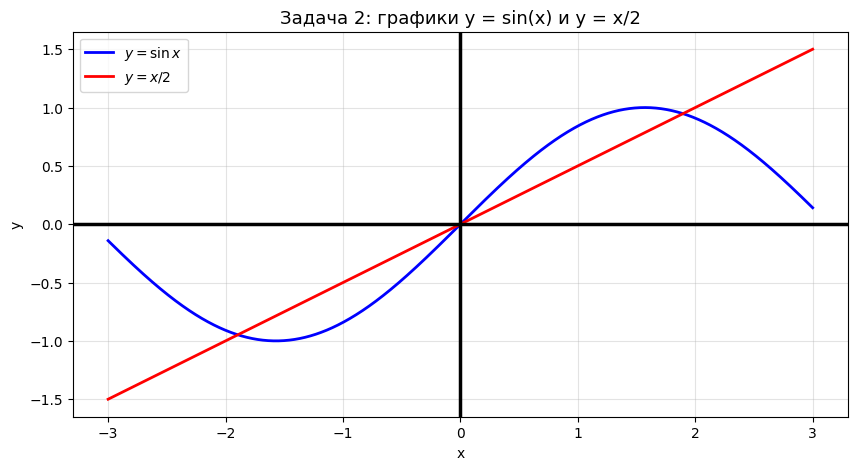

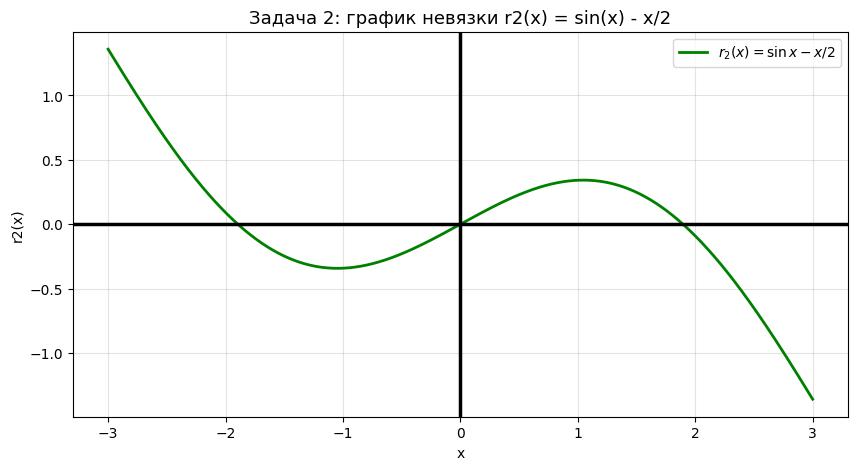

In [57]:
plot_two_functions(
    np.sin,
    lambda x: x / 2,
    -3,
    3,
    title="Задача 2: графики y = sin(x) и y = x/2",
    label1=r"$y=\sin x$",
    label2=r"$y=x/2$",
    color1="blue",
    color2="red"
)

plot_one_function(
    residual2,
    -3,
    3,
    title="Задача 2: график невязки r2(x) = sin(x) - x/2",
    label=r"$r_2(x)=\sin x - x/2$",
    color="green",
    ylabel="r2(x)"
)